# Particle motion in magnetic fields

## The Lorentz force 

The force on a charged particle (with charge $\bf q$ and velocity $\bf v$ ) in the presence of an electric field $\bf E$ and
magnetic field $\bf B$ is given by the Lorentz force law, 

$$ 
\begin{equation}
F_{\rm Lorentz} = q \left({\bf E} + {\bf v} \times {\bf B} \right)
\end{equation}
$$

In a dipole magnet, there is no electric field (${\bf E} =0$) and the magnetic field is in the vertical direction ${\bf B} = B_y \hat{{\bf j}}$. For a charged particle moving in the $z$ direction we have,

$$
\begin{equation}
F_{\rm dipole} = q {\rm v}\hat{{\bf k}}  \times {\bf B_{y} \hat{{\bf j}}} = q v B_y \hat{{\bf i}}
\end{equation}
$$

So the magnetic force is in the $x$ direction with amplitude given by $qvB_y$

## Solving for motion

We need to solve for the particle position and velocity so we can start with Newton's second law,

$$
\begin{equation}
{\bf F} = \frac{d{\bf p}}{dt}
\end{equation}
$$

where for momentum ${\bf p} = \gamma m {\bf v}$ we have,

$$
\begin{equation}
{\bf F} = \gamma m \frac{d {\bf v}}{dt}
\end{equation}
$$

Rearranging and integrating gives the velocity,

$$
\begin{equation}
{\bf v} = \frac{{\bf F} \delta t}{m \gamma} + {\bf v}_0
\end{equation}
$$

And integrating again gives the position,

$$
\begin{equation}
{\bf r} = \frac{{\bf F} \delta t^2}{2 m \gamma} + {\bf v}_0 \delta t + {\bf r}_0 
\tag{1}
\end{equation}
$$

By rearranging and substituting, we see that the velocity can be approximated by,

$$
\begin{equation}
{\bf v} = \frac{{\bf r} - {\bf r_0}}{\delta t}
\end{equation}
$$

# Solving for ${\bf r}$ in python

To model the particle motion in the dipole magnet, we can divide the path taken by the particle into small steps. After each step, we recalculate or "update" the position and velocity, which can then be used for the next step. Here is an example of an "update function":

In [1]:
import numpy as np   # loads the Numerical Python library 

# particle parameters
m = 9.11e-31         # mass
gamma = 490          # relativistic gamma factor
q = -1.6e-19         # charge
c = 2.99792458e8     # speed of light

# defines our update function
def update(v, r, dt, B = 1):                        # magnetic field set to 1 T                                             
    B = np.array([0,B,0])                           # magnetic field (only contains y component)
    F = q*np.cross(v,B)                             # Lorentz force
    v1 = F*dt/(m*gamma) + v                         # velocity (dependent on time step dt)
    r1 = F*dt**2/(2*m*gamma) + v*dt + r             # position (dependent on time step dt)
    return v1, r1

Here is example of using the update function. The initial position is $(0,0,0)$ and the velocity is $(0,0,c)$. The update is run 1000 times for a time step of $\delta t = 1 \times 10^{-12}\,\rm s = 1\, \rm ps$ (a distance of $0.3\, \rm mm$ each step when travelling at the speed of light). The position and velocity for each time step are stored in lists or arrays which can be used for plotting.

Matplotlib is building the font cache; this may take a moment.


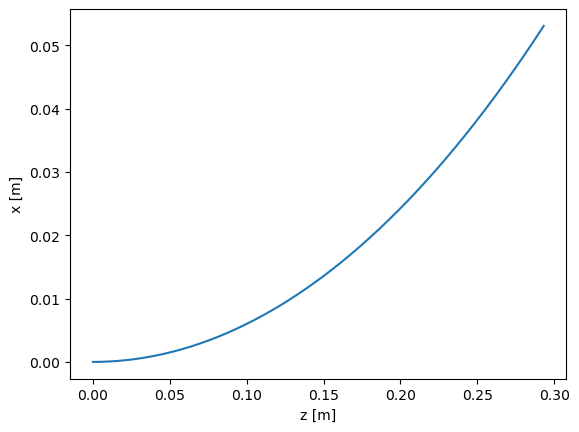

In [2]:
# initial position and velocity
r = np.array([0,0,0])                          
v = np.array([0,0,c])              

# arrays to store position and velocity for plotting and analysis later
rarray = []                                   
varray = []                                    

# time step parameters
dt = 1e-12             # time step
n_steps = 1000         # number of time steps

# loop over time steps and compute new position and velocity
for i in range(n_steps):                                   
    rarray.append(r)
    varray.append(v)
    v,r = update(v,r,dt)         

# convert lists to arrays for easier plotting 
rarray = np.array(rarray)
varray = np.array(varray)

# make a plot of position x as a function of position z
import matplotlib.pyplot as plt                # loads library of plotting functions
fig1 = plt.plot(rarray[:,2], rarray[:,0],"-")         # note: python uses zero-based indexing: (index 2 = column 3 = z) and (index 0 = column 1 = x)
plt.xlabel("z [m]");                           
plt.ylabel("x [m]");

# Exercises

(1) Using this simple model you can map out the particle trajectory in a dipole magnetic field.

> (a) What happens if you double the magnetic field from $1\, \rm T$ to $2\, \rm T$?
>
> (b) Plot the trajectory for an electron with an energy of $1\, \rm GeV$?

> (c) Can you make the particle travel one complete circle? How much time does this take? What happens if you run the code over even longer times?

> (d) For a magnetic field of $B = 8.3\, \rm T$, how long does it take protons with $7\, \rm TeV$ energy to make one complete orbit around the ring?
> (these are parameters similar to the Large Hadron Collider)

(2) In a real particle accelerator, dipole magnets have a finite length (i.e. they don't operate over all space).

> (a) Using the original starting parameters for a $250\, \rm MeV$ electron, plot the particle trajectory for a $1\,\rm T$ dipole magnet of length $30\,\rm cm$. Hint: Use an "if else statement" to apply the magnetic field.
>
> (b) What is the bending angle of the dipole magnet?

(3) Extension: We can focus particle beams using quadrupole magnets.

> (a) Make an update function for a quadrupole magnet to focus particles with different x offsets. Remember for a quadrupole $B_y = \frac{dB}{dx} x = gx$, where $g$ is the magnetic field gradient. To focus a $250\, \rm MeV$ electron beam with an extent of $\pm 1\, \rm mm$, a typical quadrupole is $15\, \rm cm$ long with a gradient of $5\, \rm T/m$.
>
> (b) What is the focal length of the quadrupole magnet?
>
> (c) Can you focus with a dipole magnet? Plot a full circular orbit (don't worry about the finite dipole length) with x offsets (just like the quadrupole) to explore.

# Solutions

# 1(a) - double the magnetic field
Use same code as above. Change value of the magnetic field $B$ to 2. The bending radius will double.

# 1(b) - 1 GeV electron
Use same code as above. For a 1 GeV electron, $\gamma = 1000/0.511 = 1957$, which is a factor of 4 higher than before. Bending radius will reduce by a factor of 4.

# 1(c) - full circular orbit and spiral motion
Use same code as above. To make a complete circle the number of time steps ($n_{\rm steps}$) and/or size of the time step ($dt$) will need to be increased. For a $1\, \rm GeV$ electron and $B = 2\, \rm T$, the total time taken to complete one circular orbit ($dt \times n_{\rm steps}$) should be around $35\, \rm ns$.

If you keep increasing the total time (time step or number of steps), the trajectory will spiral outwards. This is a limitation of the integration step used in this method. It can be improved by numerical integrators (e.g. Runge-Kutta) but to achieve true stability over millions of turns "symplectic integrators" are required. This is beyond the scope of the course. 

# 1(d) - LHC parameters (if only one giant magnet was used!)

For a $7\, \rm TeV$ proton, need to change particle mass to $1.67 \times 10^{-27}\, \rm kg$, and calculate $\gamma = 7 \times 10^6\, \rm MeV/938\, \rm MeV = 7463$, and change charge to positive sign (which will change the orbit direction). Magnetic field needs to be changed to $8.3\, \rm T$.

Total time for one full orbit should be around $59\, \mu \rm s$ giving a circumference of around $17.7\, \rm km$.

total time (s) = 5.9000000000000004e-05
total distance (m) = 17687.755022


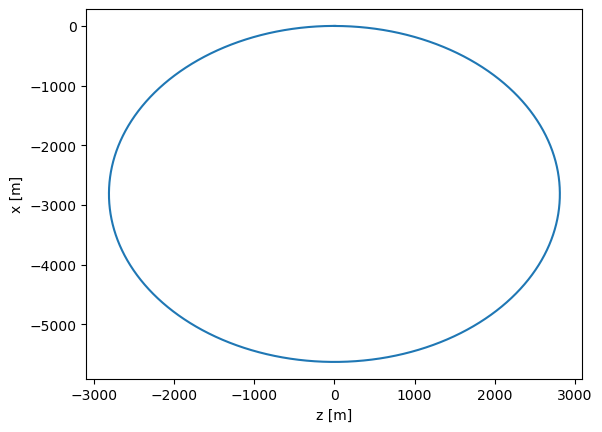

In [3]:
import numpy as np   # loads the Numerical Python library 

# particle parameters
m = 1.67e-27         # mass
gamma = 7e6/938;     # relativistic gamma factor
q = 1.6e-19          # charge
c = 2.99792458e8     # speed of light

# defines our update function
def update(v, r, dt, B = 8.3):                                                                     
    B = np.array([0,B,0])                           # magnetic field (only contains y component)
    F = q*np.cross(v,B)                             # Lorentz force
    v1 = F*dt/(m*gamma) + v                         # velocity (dependent on time step dt)
    r1 = F*dt**2/(2*m*gamma) + v*dt + r             # position (dependent on time step dt)
    return v1, r1

# initial position and velocity
r = np.array([0,0,0])                          
v = np.array([0,0,c])              

# arrays to store position and velocity for plotting and analysis later
rarray = []                                   
varray = []                                    

# time step parameters
dt = 1e-9                                      # time step
num_steps = 59000                              # number of time steps
total_time = dt*num_steps                      # total time
total_distance = total_time*c                  # total distance travelled for v = c

print('total time (s) =', total_time)
print('total distance (m) =', total_distance)

# loop over time steps and compute new position and velocity
for i in range(num_steps):                                   
    rarray.append(r)
    varray.append(v)
    v,r = update(v,r,dt)         

# convert lists to arrays for easier plotting 
rarray = np.array(rarray)
varray = np.array(varray)

# make a plot of position x as a function of position z
import matplotlib.pyplot as plt                # loads library of plotting functions
plt.plot(rarray[:,2], rarray[:,0],"-")         # note: python uses zero-based indexing: (index 2 = column 3 = z) and (index 0 = column 1 = x)
plt.xlabel("z [m]");                           
plt.ylabel("x [m]");

## 2(a) - finite dipole length

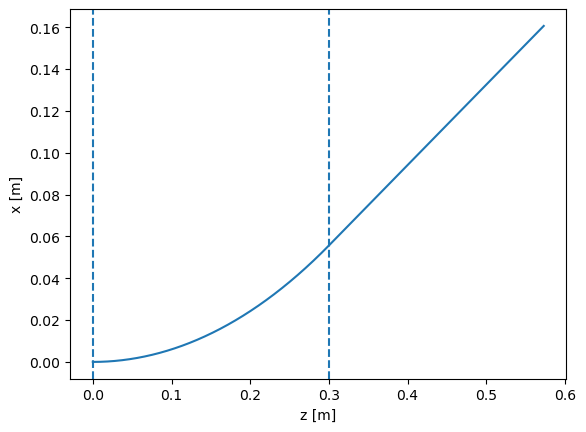

In [14]:
import numpy as np      # loads the Numerical Python library 

# particle parameters
m = 9.11e-31        # mass
gamma = 490;        # relativistic gamma factor
q = -1.6e-19        # charge
c = 2.99792458e8    # speed of light

# position and velocity update function (only apply field for z < L)
def update(v, r, dt, B=1, L=0.3) : 
    if r[2] < L:
        B = np.array([0,B,0])        
    else :
        B = np.array([0,0,0])
    F = q*np.cross(v,B)
    v1 = F*dt/(m*gamma) + v
    r1 = F*dt**2/(2*m*gamma) + v*dt + r
    return v1,r1

# initial position and velocity
r = np.array([0,0,0])                          
v = np.array([0,0,c])              

# arrays to store position and velocity for plotting and analysis later
rarray = []                                   
varray = []  

# time step parameters
dt = 1e-12                                 # time step
n_steps = 2000                             # number of time steps

# loop over time steps and compute new position and velocity
for i in range(n_steps):                         
    rarray.append(r)
    varray.append(v)
    v,r = update(v,r,dt)              

# convert lists to arrays for easier plotting 
rarray = np.array(rarray)
varray = np.array(varray)

# make a plot of position x as a function of position z
import matplotlib.pyplot as plt                
plt.plot(rarray[:,2], rarray[:,0],"-")  
plt.axvline(0.0, linestyle="--")
plt.axvline(0.3, linestyle="--")
plt.xlabel("z [m]");
plt.ylabel("x [m]");

## (3) Extension: quadrupole magnet 

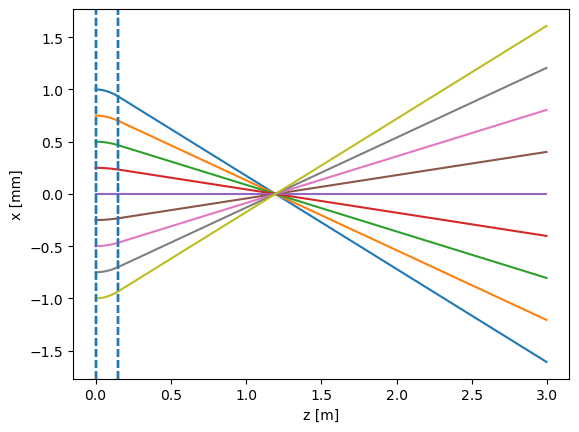

In [3]:
import numpy as np   

# particle parameters
m = 9.11e-31        # mass
gamma = 490;        # relativistic gamma factor
q = -1.6e-19        # charge
c = 2.99792458e8    # speed of light

# position and velocity update function (only apply field for z < L)
def update(v, r, dt, g=-5, L=0.15) :     # length (L) and gradient (g) in T/m of the quadrupole magnet
    if r[2] < L :
        B = np.array([0,g*r[0],0])       
    else :
        B = np.array([0,0,0])
    F = q*np.cross(v,B)
    v1 = F*dt/(m*gamma) + v
    r1 = F*dt**2/(2*m*gamma) + v*dt + r
    return v1,r1

# time step parameters
dt = 1e-11                   # time step
n_steps = 1000               # number of time steps 

# define a function for a particle trajectory with initial position r and velocity v for a number of time steps. 
def trajectory(v,r,n_steps) :
    varray = [] 
    rarray = []

    # loop over time steps and compute new position and velocity
    for i in range(n_steps) : 
        varray.append(v)
        rarray.append(r)
        v,r = update(v,r,dt)
    
    # convert lists to arrays for easier plotting 
    varray = np.array(varray)  
    rarray = np.array(rarray)
   
    return varray, rarray

import matplotlib.pyplot as plt    
for x in np.linspace(1e-3, -1e-3, 9) : # make an array of 9 x-offsets ranging from -1 mm to + 1 mm 
    varray, rarray = trajectory(np.array([0,0,c]),np.array([x,0,0]), n_steps)
    plt.plot(rarray[:,2], rarray[:,0]*1e3,"-")
    plt.axvline(0.0, linestyle="--")
    plt.axvline(0.15, linestyle="--")
    plt.xlabel("z [m]");
    plt.ylabel("x [mm]");

## (3) Extension: focusing with a dipole magnet 

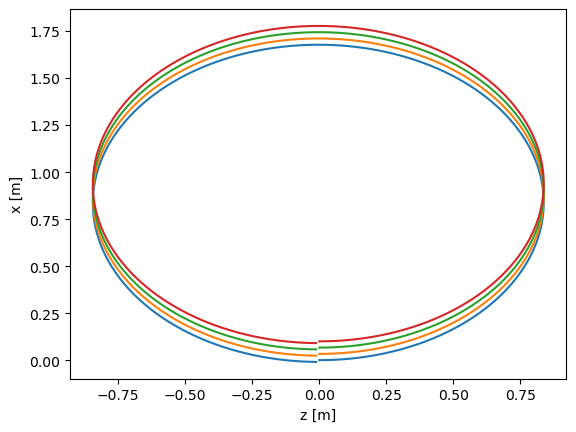

In [23]:
import numpy as np   

# particle parameters
m = 9.11e-31        # mass
gamma = 490;        # relativistic gamma factor
q = -1.6e-19        # charge
c = 2.99792458e8    # speed of light

# position and velocity update function (only apply field for z < L)
def update(v, r, dt, B=1) :    
    B = np.array([0,B,0])       
    F = q*np.cross(v,B)
    v1 = F*dt/(m*gamma) + v
    r1 = F*dt**2/(2*m*gamma) + v*dt + r
    return v1,r1

# time step parameters
dt = 1e-11                   # time step
n_steps = 1750               # number of time steps

# calculate a particle trajectory for initial position r and velocity v for a number of time steps. 
def trajectory(v,r,n_steps) :
    varray = [] 
    rarray = []

    # loop over time steps and compute new position and velocity
    for i in range(n_steps) : 
        varray.append(v)
        rarray.append(r)
        v,r = update(v,r,dt)
    
    # convert lists to arrays for easier plotting 
    varray = np.array(varray)  
    rarray = np.array(rarray)
   
    return varray, rarray

import matplotlib.pyplot as plt    
for x in np.linspace(0, 100e-3, 4) :
    varray, rarray = trajectory(np.array([0,0,c]),np.array([x,0,0]), n_steps)
    plt.plot(rarray[:,2], rarray[:,0],"-")
    plt.xlabel("z [m]");
    plt.ylabel("x [m]");